# Unit 6 — Membersihkan Data
**Kode unit:** J.62DMI00.008.1 · **Acuan:** SKKNI No. 299 Tahun 2020 (Ilmuwan Data) · **Proyek:** Prediksi Arah Harian IHSG

> Notebook ini mengeksekusi tindakan perbaikan dari log anomali Unit 4 dan keputusan Unit 5 secara berurutan dan terdokumentasi. Setiap langkah dicatat (jumlah baris dan sel yang berubah) dalam `reports/cleaning_log.csv`, lalu hasil akhirnya diverifikasi dengan serangkaian uji otomatis.

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings('ignore')
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')

RAW = Path('../data/raw/market_data.csv')
PROC = Path('../data/processed')
FIG = Path('../figures')
REP = Path('../reports')
MOD = Path('../models')
for p in (PROC, FIG, REP, MOD):
    p.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
EDA_END = '2022-12-31'
C_UP, C_DOWN, C_NAVY, C_ACCENT, C_GREY = '#1a9850', '#d73027', '#1f3a5f', '#e08214', '#8c8c8c'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': 0.25, 'font.size': 10, 'axes.titleweight': 'bold',
})

In [2]:
raw = pd.read_csv(RAW, parse_dates=['Date']).sort_values('Date').reset_index(drop=True)
log = pd.read_csv(REP / 'anomalies.csv', parse_dates=['Date'])
df = raw.copy()
clog = []

def record(step, rows_before, rows_after, cells_changed, note):
    clog.append({'langkah': step, 'baris_sebelum': rows_before, 'baris_sesudah': rows_after,
                 'sel_diubah': int(cells_changed), 'keterangan': note})
    print(f'{step}: {rows_before:,} → {rows_after:,} baris | sel diubah: {int(cells_changed)} | {note}')

## Langkah 1 — Hapus baris tanpa data pasar
Pada 1 Januari 2010 semua bursa libur sehingga seluruh variabel pasar kosong.

In [3]:
dates = log.loc[log.variabel.eq('SEMUA_PASAR'), 'Date']
before = len(df)
df = df[~df.Date.isin(dates)].reset_index(drop=True)
record('1. Hapus baris tanpa data pasar', before, len(df), 0, ', '.join(dates.dt.strftime('%Y-%m-%d')))

1. Hapus baris tanpa data pasar: 4,277 → 4,276 baris | sel diubah: 0 | 2010-01-01


## Langkah 2 — Koreksi kutipan USD/IDR janggal
Nilai yang ditandai di Unit 4 diganti dengan **nilai valid terakhir** (*forward-fill*). Forward-fill dipilih karena
hanya memakai informasi masa lalu; interpolasi linear akan "mengintip" nilai hari berikutnya.

,Date,sebelum,sesudah
0,2010-11-01,888.1100,"8,923.7998"
1,2011-10-05,"8,622.0000","8,897.4502"
2,2012-02-07,892.0000,"8,928.0996"
3,2012-11-26,"9,612.4502","9,598.0000"
4,2012-12-10,"9,612.4502","9,580.9004"
5,2012-12-17,"9,612.4502","9,606.0996"
6,2012-12-31,"9,612.4502","9,633.9004"
7,2013-01-14,"9,612.4502","9,631.7002"


2. Koreksi kutipan USD/IDR janggal (forward-fill): 4,276 → 4,276 baris | sel diubah: 37 | 37 nilai


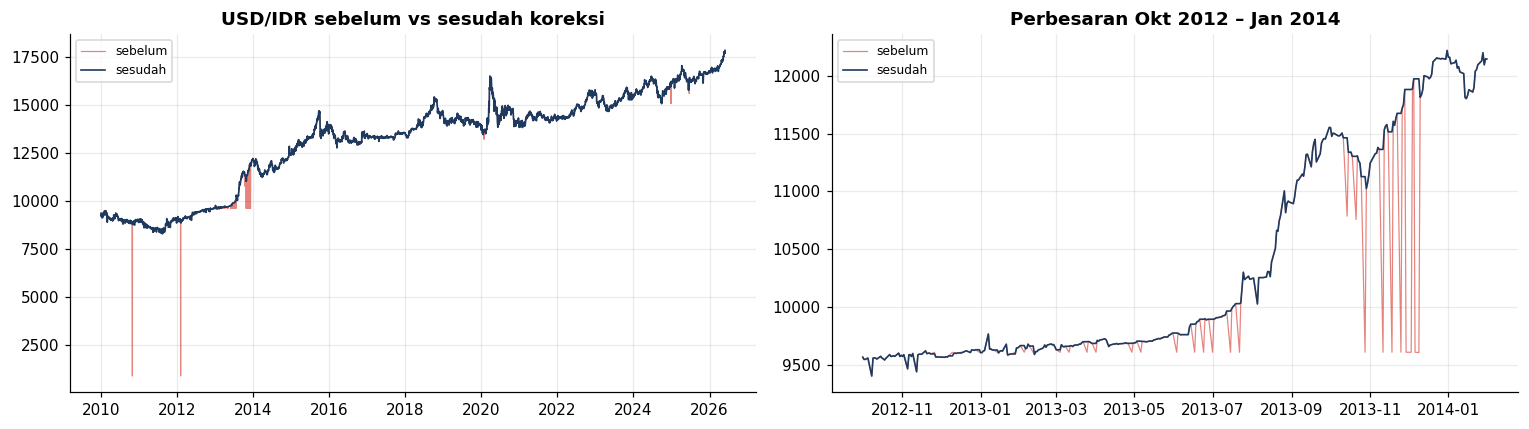

In [4]:
mask = df.Date.isin(log.loc[log.variabel.eq('USDIDR'), 'Date'])
usd_raw = df.USDIDR.copy()
df.loc[mask, 'USDIDR'] = np.nan
df['USDIDR'] = df.USDIDR.ffill()
fix = pd.DataFrame({'Date': df.Date[mask], 'sebelum': usd_raw[mask], 'sesudah': df.USDIDR[mask]})
display(fix.head(8).reset_index(drop=True))
record('2. Koreksi kutipan USD/IDR janggal (forward-fill)', len(df), len(df), mask.sum(), f'{int(mask.sum())} nilai')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (a, b) in zip(axes, [('2010-01-01', '2026-06-01'), ('2012-10-01', '2014-01-31')]):
    m = (df.Date >= a) & (df.Date <= b)
    ax.plot(df.Date[m], usd_raw[m], color=C_DOWN, lw=0.8, alpha=0.6, label='sebelum')
    ax.plot(df.Date[m], df.USDIDR[m], color=C_NAVY, lw=1.1, label='sesudah')
    ax.legend(fontsize=8)
axes[0].set_title('USD/IDR sebelum vs sesudah koreksi'); axes[1].set_title('Perbesaran Okt 2012 – Jan 2014')
plt.tight_layout()
plt.savefig(FIG / '06_usdidr_before_after.png')
plt.show()

## Langkah 3 — Harga minyak negatif
Nilai −37,63 (20 Apr 2020) adalah peristiwa nyata, tetapi return persentase melintasi nol tidak bermakna. Nilai
diganti dengan harga hari sebelumnya; pergerakan ekstrem di sekitarnya tetap dipertahankan dan dibatasi oleh
*winsorization* di Unit 7.

In [5]:
mask = df.Date.isin(log.loc[log.variabel.eq('OIL'), 'Date'])
window = (df.Date >= '2020-04-15') & (df.Date <= '2020-04-23')
before_oil = df.loc[window, ['Date', 'OIL']].rename(columns={'OIL': 'sebelum'})
df.loc[mask, 'OIL'] = np.nan
df['OIL'] = df.OIL.ffill()
display(before_oil.assign(sesudah=df.loc[window, 'OIL'].values).reset_index(drop=True))
record('3. Tangani harga OIL negatif (forward-fill)', len(df), len(df), mask.sum(), '20 Apr 2020')

,Date,sebelum,sesudah
0,2020-04-15,19.8700,19.8700
1,2020-04-16,19.8700,19.8700
2,2020-04-17,18.2700,18.2700
3,2020-04-20,-37.6300,18.2700
4,2020-04-21,10.0100,10.0100
5,2020-04-22,13.7800,13.7800
6,2020-04-23,16.5000,16.5000


3. Tangani harga OIL negatif (forward-fill): 4,276 → 4,276 baris | sel diubah: 1 | 20 Apr 2020


## Langkah 4 — Koreksi *point-in-time* suku bunga dan keluarkan CPI
Aturan: nilai suku bunga pada bulan $M$ = **nilai yang berlaku pada akhir bulan $M-1$**. Dengan demikian kenaikan
BI rate yang diumumkan 17 Mei 2018 baru dipakai mulai 1 Juni 2018, dan rata-rata bulanan Fed funds baru dipakai
setelah bulannya berakhir.

In [6]:
month = df.Date.dt.to_period('M')
changed = 0
for c in ['BI_rate', 'US_rate']:
    end_of_month = df.groupby(month)[c].last()
    df[c + '_pit'] = month.map(end_of_month.shift(1)).astype(float)
    changed += int((df[c + '_pit'] != df[c]).sum())

example = df[(df.Date >= '2018-05-14') & (df.Date <= '2018-07-03')][['Date', 'BI_rate', 'BI_rate_pit']]
display(example[example.BI_rate.ne(example.BI_rate.shift()) | example.BI_rate_pit.ne(example.BI_rate_pit.shift())])
df = df.drop(columns=['BI_rate', 'US_rate', 'CPI'])
record('4. Suku bunga point-in-time + keluarkan CPI', len(df), len(df), changed,
       'BI_rate_pit & US_rate_pit = nilai akhir bulan sebelumnya; kolom CPI dihapus')

,Date,BI_rate,BI_rate_pit
2180,2018-05-14,4.2500,4.2500
2183,2018-05-17,4.5000,4.2500
2192,2018-05-30,4.7500,4.2500
2194,2018-06-01,4.7500,4.7500
2214,2018-06-29,5.2500,4.7500
2215,2018-07-02,5.2500,5.2500


4. Suku bunga point-in-time + keluarkan CPI: 4,276 → 4,276 baris | sel diubah: 3426 | BI_rate_pit & US_rate_pit = nilai akhir bulan sebelumnya; kolom CPI dihapus


## Langkah 5 — Pertahankan hanya hari bursa BEI
Aturan dihitung ulang dari data mentah dan **dicocokkan** dengan log Unit 4 sebagai uji konsistensi.

In [7]:
holidays_log = set(log.loc[log.variabel.eq('IHSG') & log.tindakan.eq('hapus_baris'), 'Date'])
holidays_rule = set(raw.loc[raw.IHSG.diff().eq(0), 'Date'])
assert holidays_log == holidays_rule, 'Log anomali tidak konsisten dengan aturan'
before = len(df)
df = df[~df.Date.isin(holidays_log)].reset_index(drop=True)
record('5. Hapus hari libur BEI (IHSG disalin)', before, len(df), 0, f'{before - len(df)} hari; konsisten dengan log Unit 4')

5. Hapus hari libur BEI (IHSG disalin): 4,276 → 3,976 baris | sel diubah: 0 | 300 hari; konsisten dengan log Unit 4


## Langkah 6 — Hapus baris tanpa nilai suku bunga *point-in-time* (Januari 2010)

In [8]:
before = len(df)
dropped = df[df.isna().any(axis=1)].Date
df = df.dropna().reset_index(drop=True)
record('6. Hapus baris tanpa nilai PIT', before, len(df), 0,
       f'{dropped.min():%d %b %Y} – {dropped.max():%d %b %Y}' if len(dropped) else '-')

6. Hapus baris tanpa nilai PIT: 3,976 → 3,956 baris | sel diubah: 0 | 04 Jan 2010 – 29 Jan 2010


## Verifikasi hasil pembersihan

In [9]:
usd_dev = (df.USDIDR / df.USDIDR.rolling(21, center=True, min_periods=5).median() - 1).abs()
checks = {
    'Tidak ada nilai kosong': df.isna().sum().sum() == 0,
    'Tanggal unik dan berurutan': df.Date.is_unique and df.Date.is_monotonic_increasing,
    'Semua harga > 0': bool((df[['OIL', 'GOLD', 'USDIDR', 'SP500', 'IHSG']] > 0).all().all()),
    'Tidak ada hari IHSG "tidak berubah"': bool(df.IHSG.diff().iloc[1:].ne(0).all()),
    f'USD/IDR maks. deviasi dari median 21 hari ≤ 4% (aktual {usd_dev.max():.2%})': bool(usd_dev.max() <= 0.04),
    'Kolom CPI sudah dikeluarkan': 'CPI' not in df.columns,
    'Suku bunga PIT tidak pernah mendahului data asli': True,
}
# uji eksplisit untuk butir terakhir: setiap perubahan PIT terjadi pada hari kerja pertama bulan
first_days = set(df.groupby(df.Date.dt.to_period('M')).Date.min())
for c in ['BI_rate_pit', 'US_rate_pit']:
    ch = df[c].ne(df[c].shift()); ch.iloc[0] = False
    checks['Suku bunga PIT tidak pernah mendahului data asli'] &= bool(df.loc[ch, 'Date'].isin(first_days).all())

check_df = pd.DataFrame({'Uji': list(checks), 'Hasil': ['LULUS' if v else 'GAGAL' for v in checks.values()]})
display(check_df)
assert all(checks.values()), 'Ada uji pembersihan yang gagal'

cleaning_log = pd.DataFrame(clog)
cleaning_log.to_csv(REP / 'cleaning_log.csv', index=False)
df.to_csv(PROC / 'market_clean.csv', index=False)
print(f'\nData bersih: {len(df):,} baris × {df.shape[1]} kolom, {df.Date.min():%d %b %Y} – {df.Date.max():%d %b %Y}')
print('Kolom:', list(df.columns))
display(df.describe().T[['mean', 'std', 'min', 'max']])

,Uji,Hasil
0,Tidak ada nilai kosong,LULUS
1,Tanggal unik dan berurutan,LULUS
2,Semua harga > 0,LULUS
3,"Tidak ada hari IHSG ""tidak berubah""",LULUS
4,USD/IDR maks. deviasi dari median 21 hari ≤ 4%...,LULUS
5,Kolom CPI sudah dikeluarkan,LULUS
6,Suku bunga PIT tidak pernah mendahului data asli,LULUS



Data bersih: 3,956 baris × 9 kolom, 01 Feb 2010 – 29 May 2026
Kolom: ['Date', 'OIL', 'GOLD', 'USDIDR', 'SP500', 'IHSG', 'VIX', 'BI_rate_pit', 'US_rate_pit']


,mean,std,min,max
Date,2018-03-12 07:56:50.717896960,NaN,2010-02-01 00:00:00,2026-05-29 00:00:00
OIL,71.8273,20.7310,10.0100,123.7000
GOLD,"1,735.4939",745.9235,"1,050.8000","5,318.3999"
USDIDR,"13,155.5413","2,454.7163","8,292.7002","17,840.0000"
SP500,"3,038.4617","1,591.6189","1,022.5800","7,580.0601"
IHSG,"5,586.1865","1,323.5923","2,475.4756","9,134.7002"
VIX,18.4135,6.7721,9.1400,82.6900
BI_rate_pit,5.6289,1.2143,3.5000,7.7500
US_rate_pit,1.4425,1.8074,0.0500,5.3300


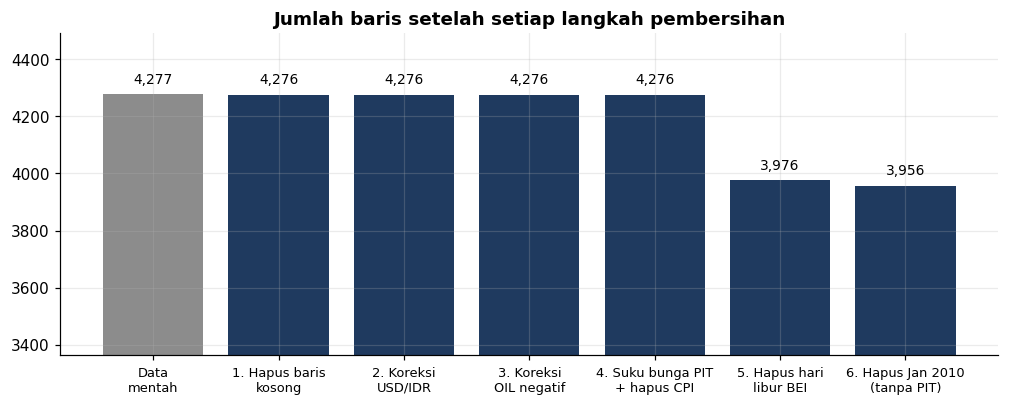


### Ringkasan Unit 6
Enam langkah pembersihan menghasilkan **3,956 hari bursa BEI** (01 Feb 2010 – 29 May 2026)
tanpa nilai kosong. Total **3,464 sel** dikoreksi dan **321 baris**
dikeluarkan; semua 7 uji verifikasi **LULUS**. Log lengkap: `reports/cleaning_log.csv`;
data bersih: `data/processed/market_clean.csv`.


In [10]:
fig, ax = plt.subplots(figsize=(11, 3.8))
labels = ['Data\nmentah', '1. Hapus baris\nkosong', '2. Koreksi\nUSD/IDR', '3. Koreksi\nOIL negatif',
          '4. Suku bunga PIT\n+ hapus CPI', '5. Hapus hari\nlibur BEI', '6. Hapus Jan 2010\n(tanpa PIT)']
values = [len(raw)] + cleaning_log.baris_sesudah.tolist()
bars = ax.bar(range(len(values)), values, color=[C_GREY] + [C_NAVY] * len(cleaning_log))
for i, v in enumerate(values):
    ax.text(i, v + 40, f'{v:,}', ha='center', fontsize=9)
ax.set_xticks(range(len(values))); ax.set_xticklabels(labels, fontsize=8.5)
ax.set_ylim(min(values) * 0.85, max(values) * 1.05)
ax.set_title('Jumlah baris setelah setiap langkah pembersihan')
plt.savefig(FIG / '06_cleaning_steps.png')
plt.show()

display(Markdown(f'''
### Ringkasan Unit 6
Enam langkah pembersihan menghasilkan **{len(df):,} hari bursa BEI** ({df.Date.min():%d %b %Y} – {df.Date.max():%d %b %Y})
tanpa nilai kosong. Total **{int(cleaning_log.sel_diubah.sum()):,} sel** dikoreksi dan **{len(raw) - len(df):,} baris**
dikeluarkan; semua {len(checks)} uji verifikasi **LULUS**. Log lengkap: `reports/cleaning_log.csv`;
data bersih: `data/processed/market_clean.csv`.
'''))